# Task 4.3


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits

threadpool_limits(limits=1)
FAST = True


In [2]:
def std(x, m=None, s=None):
    if m is None:
        m = x.mean(axis=0)
        s = x.std(axis=0)
        s = np.where(s < 1e-12, 1, s)
    return (x - m) / s, m, s


def poly(x):
    c = [np.ones(len(x))]
    for i in range(x.shape[1]):
        c.append(x[:, i])
    for i in range(x.shape[1]):
        for j in range(i, x.shape[1]):
            c.append(x[:, i] * x[:, j])
    return np.column_stack(c)


def pnames(nm):
    s = ['bias'] + list(nm)
    for i in range(len(nm)):
        for j in range(i, len(nm)):
            s.append(str(nm[i]) + ' * ' + str(nm[j]))
    return s


def design(tr, te=None):
    x, m0, s0 = std(tr)
    x, m, s = std(poly(x)[:, 1:])
    z = np.column_stack([np.ones(len(x)), x])
    if te is None:
        return z
    x0, _, _ = std(te, m0, s0)
    x0, _, _ = std(poly(x0)[:, 1:], m, s)
    return z, np.column_stack([np.ones(len(x0)), x0])


def soft(w, t):
    return np.sign(w) * np.maximum(np.abs(w) - t, 0)


def canon(z, w):
    w = w.copy()
    for j in range(1, z.shape[1]):
        for i in range(1, j):
            s = 0
            if np.allclose(z[:, j], z[:, i], rtol=1e-10, atol=1e-10):
                s = 1
            elif np.allclose(z[:, j], -z[:, i], rtol=1e-10, atol=1e-10):
                s = -1
            if s:
                w[..., i] += s * w[..., j]
                w[..., j] = 0
                break
    return w


def ista(z, y, l, w, tol=1e-10):
    g = z.T @ z / len(y)
    b = z.T @ y / len(y)
    h = 1 / (2*np.linalg.eigvalsh(g)[-1])
    p = np.ones(z.shape[1])
    p[0] = 0
    w = w.copy()
    for i in range(300000):
        v = soft(w - 2*h*(g @ w - b), h*l*p)
        err = np.max(np.abs(v - w)) / h
        w = v
        if err < tol:
            return w
    raise RuntimeError('ISTA did not converge')


def ridge(z, y, ls):
    m = z[:, 1:].mean(axis=0)
    b = y.mean()
    x = z[:, 1:] - m
    u, s, vt = np.linalg.svd(x, full_matrices=False)
    d = s[None, :]**2 + np.asarray(ls)[:, None]
    t = s[None, :] / d
    w = (t * (u.T @ (y - b))) @ vt
    h = (t * s) @ (u**2).T + 1/len(y)
    w = np.column_stack([b - w @ m, w])
    return w, h


In [3]:
from sklearn.datasets import load_diabetes

ds = load_diabetes(scaled=False)
rng = np.random.default_rng(407)
idx = rng.permutation(len(ds.target))
te = idx[:round(0.2 * len(idx))]
tr = idx[round(0.2 * len(idx)):]
z = design(ds.data[tr])
y = ds.target[tr]
nm = pnames(ds.feature_names)[1:]
assert z.shape[1] == 66

lm = 2 * np.max(np.abs(z[:, 1:].T @ (y - y.mean()))) / len(y)
ls = lm * np.logspace(0, -2, 25 if FAST else 41)
w1 = np.zeros((len(ls), z.shape[1]))
w = np.zeros(z.shape[1])
for j, lam in enumerate(ls):
    w = ista(z, y, lam, w, tol=1e-10)
    w1[j] = w


raw1 = w1.copy()
w1 = canon(z, w1)
assert np.allclose(z @ w1.T, z @ raw1.T, atol=1e-8)
assert np.allclose(np.abs(w1[:, 1:]).sum(axis=1),
                   np.abs(raw1[:, 1:]).sum(axis=1), atol=1e-8)

w2, _ = ridge(z, y, len(y) * ls)
print("Training rows:", len(tr), "expanded features:", len(nm))


Training rows: 354 expanded features: 65


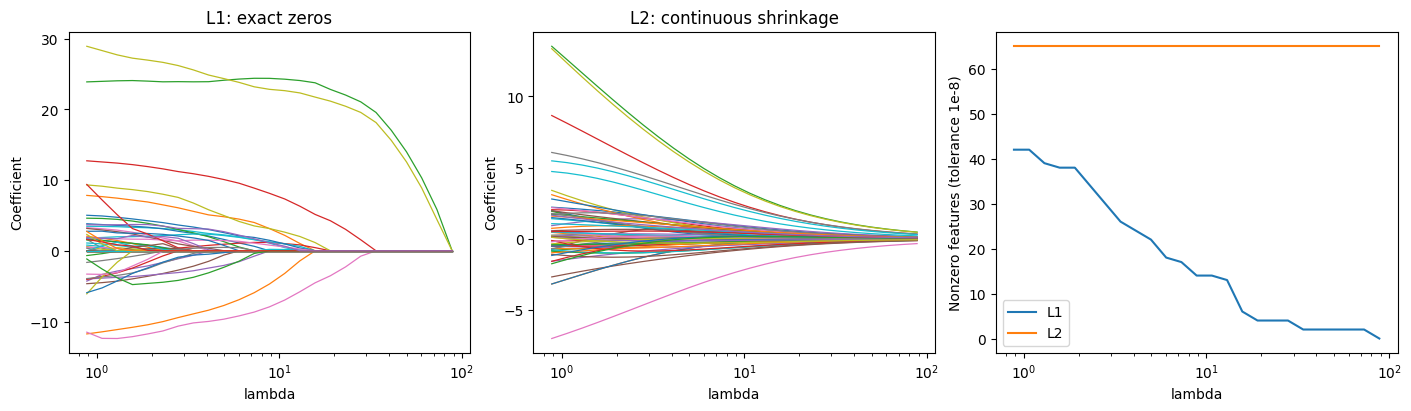

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for ax, w, ttl in [(axs[0], w1, "L1: exact zeros"),
                            (axs[1], w2, "L2: continuous shrinkage")]:
    ax.plot(ls, w[:, 1:], linewidth=0.9)
    ax.set_xscale("log")
    ax.set(xlabel="lambda", ylabel="Coefficient", title=ttl)
for w, lab in [(w1, "L1"), (w2, "L2")]:
    axs[2].plot(ls, np.sum(np.abs(w[:, 1:]) > 1e-8, axis=1), label=lab)
axs[2].set_xscale("log")
axs[2].set(xlabel="lambda", ylabel="Nonzero features (tolerance 1e-8)")
axs[2].legend()
plt.show()


Library comparison


In [5]:
from sklearn.linear_model import Lasso, Ridge

err1, err2 = [], []
raw_err, pred_err = [], []
for j, lam in enumerate(ls):
    ref1 = Lasso(alpha=lam / 2, tol=1e-12, max_iter=1000000).fit(z[:, 1:], y)
    ref2 = Ridge(alpha=len(y) * lam, solver="svd").fit(z[:, 1:], y)
    v0 = np.r_[ref1.intercept_, ref1.coef_]
    raw_err.append(np.max(np.abs(raw1[j] - v0)))
    pred_err.append(np.max(np.abs(z @ raw1[j] - ref1.predict(z[:, 1:]))))
    v1 = canon(z, v0)
    v2 = np.r_[ref2.intercept_, ref2.coef_]
    err1.append(np.max(np.abs(w1[j] - v1)))
    err2.append(np.max(np.abs(w2[j] - v2)))

print("Raw Lasso coefficient difference (nonunique duplicate):", max(raw_err))
print("Maximum Lasso prediction difference:", max(pred_err))
print("Maximum Lasso coefficient difference after consistent duplicate handling:", max(err1))
print("Maximum Ridge coefficient difference:", max(err2))
assert max(err1) < 1e-4
assert max(err2) < 1e-4


Raw Lasso coefficient difference (nonunique duplicate): 5.657909184051605
Maximum Lasso prediction difference: 1.0564065178186866e-08
Maximum Lasso coefficient difference after consistent duplicate handling: 9.509052656397898e-09
Maximum Ridge coefficient difference: 8.881784197001252e-15
